# Projeto Sprint 8 — Y.Afisha Marketing Analysis

**TripleTen Data Analyst | Luiz Trajano**

---

## Objetivo

Neste projeto, atuo como estagiário no departamento analítico da **Y.Afisha**.  
Minha tarefa: ajudar a empresa a **otimizar despesas com marketing**.

O período analisado vai de **janeiro/2017 a dezembro/2018**. Vou produzir:
- Métricas de **produto** (audiência, sessões, retenção)
- Métricas de **vendas** (conversão, pedidos, ticket médio, LTV)
- Métricas de **marketing** (gastos, CAC, ROMI por origem e dispositivo)
- **Recomendação final** fundamentada em dados

## Passo 1 — Carregamento e Preparação dos Dados

### 1.1 Leitura dos Dados

Vou carregar os três datasets nas variáveis `visits`, `orders` e `costs`.  
Uso `.sample(5)` para uma primeira inspeção aleatória — cada execução mostra linhas diferentes, o que me ajuda a perceber a variedade dos dados.

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [173]:
visits = pd.read_csv('data/visits_log_us.csv')
orders = pd.read_csv('data/orders_log_us.csv')
costs  = pd.read_csv('data/costs_us.csv')

print(visits.sample(5))
print()
print(orders.sample(5))
print()
print(costs.sample(5))

         Device               End Ts  Source Id             Start Ts  \
105226  desktop  2018-04-12 22:10:00          3  2018-04-12 22:03:00   
16448     touch  2018-03-04 16:08:00          2  2018-03-04 16:08:00   
149703  desktop  2017-08-16 15:36:00          2  2017-08-16 15:36:00   
345237  desktop  2018-02-23 21:41:00          4  2018-02-23 21:40:00   
57807     touch  2018-04-21 14:39:00          3  2018-04-21 14:10:00   

                         Uid  
105226  14535268597012460350  
16448    1662948524096248559  
149703  18418999114213506857  
345237  17868210175724775233  
57807    1832873334539569277  

                    Buy Ts  Revenue                   Uid
2279   2017-06-30 09:03:00     2.78   6930826188299344857
5926   2017-08-24 10:35:00     9.78   3286262799226938753
18116  2017-11-17 17:03:00     0.79  13068105149228630746
46597  2018-05-07 14:15:00     1.07   7266169684796475093
15327  2017-10-30 15:45:00     1.22  18160398998749529152

      source_id          dt   c

💡 **Lição Bônus em ação:** o tipo `object` é o mais pesado em memória — vou eliminá-lo onde possível.

Antes de converter qualquer coisa, uso `.info(memory_usage='deep')` para ver o peso real de cada coluna e comparo com o resultado após a otimização.

In [174]:

# Verifico tipos e memória antes da otimização
print(visits.info(memory_usage='deep'))
print()
print(orders.info(memory_usage='deep'))
print()
print(costs.info(memory_usage='deep'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 71.1 MB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   50415 non-null  object 
 1   Revenue  50415 non-null  float64
 2   Uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 4.0 MB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     -------------- 

### 1.2 Otimização dos Tipos

**Perguntas para guiar antes de codar:**
- Quais colunas estão como `object` mas representam datas?
- A coluna `Device` tem quantos valores únicos? Faz sentido convertê-la para `category`?
- Quais colunas numéricas podem usar um tipo menor que `int64` ou `float64`?

**Armadilhas que preciso evitar:**
- Uso `pd.to_datetime()` **antes** de qualquer operação `.dt` — sem isso levaria `AttributeError`
- Renomeio as colunas para `snake_case` logo no início para evitar espaços nos nomes
- Verifico nulos e duplicatas nos três DataFrames — documento o que encontrar

In [175]:
# Renomeio colunas para snake_case
visits = visits.rename(columns={
    'Uid': 'uid',
    'Device': 'device',
    'Start Ts': 'start_ts',
    'End Ts': 'end_ts',
    'Source Id': 'source_id'
})

orders = orders.rename(columns={
    'Uid': 'uid',
    'Buy Ts': 'buy_ts',
    'Revenue': 'revenue'
})
# costs já está em snake_case

# Converto colunas de data para datetime64
visits['start_ts'] = pd.to_datetime(visits['start_ts'])
visits['end_ts'] = pd.to_datetime(visits['end_ts'])
orders['buy_ts'] = pd.to_datetime(orders['buy_ts'])
costs['dt'] = pd.to_datetime(costs['dt'])

# Otimizo dtypes
visits['device'] = visits['device'].astype('category')
visits['source_id'] = visits['source_id'].astype('int8')
visits['uid'] = visits['uid'].astype('uint64')

orders['uid'] = orders['uid'].astype('uint64')
orders['revenue'] = orders['revenue'].astype('float32')

costs['source_id'] = costs['source_id'].astype('int8')
costs['costs'] = costs['costs'].astype('float32')

# Verifico nulos
print(visits.isnull().sum())
print()
print(orders.isnull().sum())
print()
print(costs.isnull().sum())

# Verifico duplicatas
print(f'\nDuplicatas visits: {visits.duplicated().sum()}')
print(f'Duplicatas orders: {orders.duplicated().sum()}')
print(f'Duplicatas costs:  {costs.duplicated().sum()}')

# Verifico tipos e memória após a otimização
print()
print(visits.info(memory_usage='deep'))
print()
print(orders.info(memory_usage='deep'))
print()
print(costs.info(memory_usage='deep'))

device       0
end_ts       0
source_id    0
start_ts     0
uid          0
dtype: int64

buy_ts     0
revenue    0
uid        0
dtype: int64

source_id    0
dt           0
costs        0
dtype: int64

Duplicatas visits: 0
Duplicatas orders: 0
Duplicatas costs:  0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   device     359400 non-null  category      
 1   end_ts     359400 non-null  datetime64[ns]
 2   source_id  359400 non-null  int8          
 3   start_ts   359400 non-null  datetime64[ns]
 4   uid        359400 non-null  uint64        
dtypes: category(1), datetime64[ns](2), int8(1), uint64(1)
memory usage: 8.9 MB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   

### Observação — Otimização de Memória

Após a conversão de tipos, a redução de memória foi significativa nos três DataFrames:

| DataFrame | Antes     | Depois    | Redução |
|-----------|-----------|-----------|---------|
| visits    | 71.1 MB   | 8.9 MB    | 87.5%   |
| orders    | 4.0 MB    | 984.8 KB  | 75.9%   |
| costs     | 186.3 KB  | 32.4 KB   | 82.6%   |

Nenhum valor nulo e nenhuma duplicata foram encontrados nos três DataFrames — os dados estão prontos para análise.

## Passo 2 — Relatórios e Métricas

### Produto

#### 2.1 Audiência — DAU, WAU e MAU

**DAU (Daily Active Users):** usuários únicos por dia  
**WAU (Weekly Active Users):** usuários únicos por semana  
**MAU (Monthly Active Users):** usuários únicos por mês  

Ao final, vou calcular a **média** de cada métrica para ter um valor representativo do período.

**Qual função uso para contar usuários únicos?**  
`nunique()` — nunca `count()`, que conta registros e não usuários distintos.

**Armadilha no MAU:**  
Agrupar só pelo número do mês mistura janeiro/2017 com janeiro/2018.  
Vou agrupar sempre por `(year, month)` ou extrair com `dt.to_period('M')`.

**Armadilha na semana:**  
`.dt.week` está depreciado e pode gerar erro de tipo.  
Uso `.dt.isocalendar().week.astype(int)` como padrão seguro.

**Pergunta:** como vou extrair dia, semana e mês de `start_ts` para usar no `groupby`?  
Preciso pensar nas colunas auxiliares que crio antes de calcular qualquer métrica.


DAU médio: 907.99

WAU médio: 5716.25

MAU médio: 23228.42


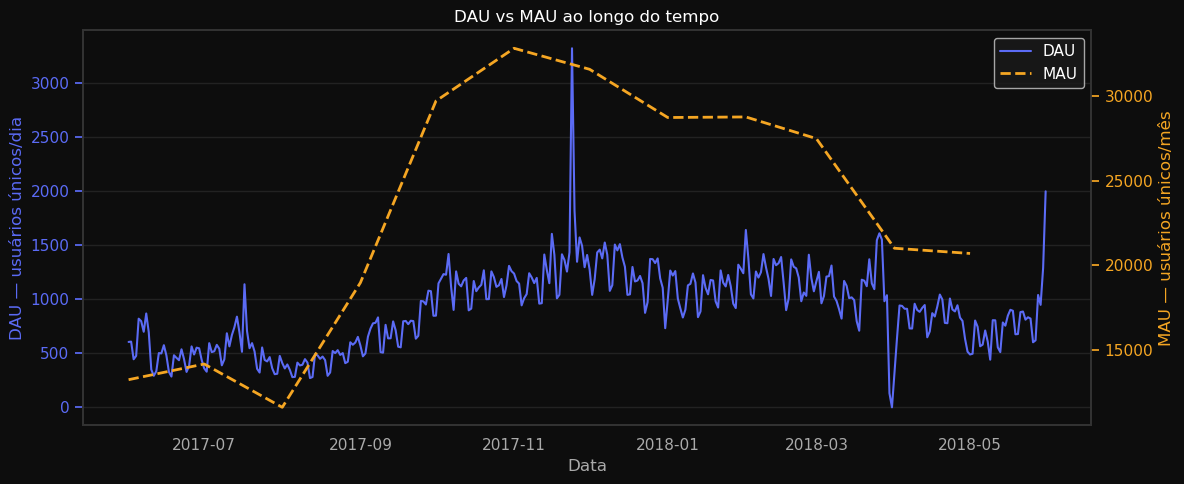

In [176]:
# Extraio colunas auxiliares de data de 'start_ts'
visits['session_date'] = visits['start_ts'].dt.date
visits['session_week'] = visits['start_ts'].dt.isocalendar().week.astype(int)
visits['session_month'] = visits['start_ts'].dt.to_period('M').dt.to_timestamp()
visits['session_year'] = visits['start_ts'].dt.year

# Calculo DAU — crio DataFrame completo para usar no gráfico
dau = visits.groupby('session_date').agg({'uid': 'nunique'})
dau_total = dau.mean().iloc[0]

# Calculo WAU
wau_total = visits.groupby(['session_year', 'session_week']).agg({'uid': 'nunique'}).mean().iloc[0]

# Calculo MAU — crio DataFrame completo para usar no gráfico
mau = visits.groupby('session_month').agg({'uid': 'nunique'})
mau_total = mau.mean().iloc[0]

print(f'\nDAU médio: {dau_total:.2f}')
print(f'\nWAU médio: {wau_total:.2f}')
print(f'\nMAU médio: {mau_total:.2f}')

# Ploto DAU vs MAU — eixo duplo (escalas muito diferentes)
fig, ax1 = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor('#0d0d0d')
ax1.set_facecolor('#0d0d0d')

ax1.plot(dau.index, dau['uid'], color='#5B6BF5', linewidth=1.5, label='DAU')
ax1.set_ylabel('DAU — usuários únicos/dia', color='#5B6BF5')
ax1.tick_params(axis='y', colors='#5B6BF5')
ax1.tick_params(axis='x', colors='#aaaaaa')

ax2 = ax1.twinx()
ax2.set_facecolor('#0d0d0d')
ax2.plot(mau.index, mau['uid'], color='#F5A623', linewidth=2, linestyle='--', label='MAU')
ax2.set_ylabel('MAU — usuários únicos/mês', color='#F5A623')
ax2.tick_params(axis='y', colors='#F5A623')

ax1.set_title('DAU vs MAU ao longo do tempo', color='white')
ax1.set_xlabel('Data', color='#aaaaaa')
for spine in ax1.spines.values():
    spine.set_edgecolor('#333333')
for spine in ax2.spines.values():
    spine.set_edgecolor('#333333')
ax1.yaxis.grid(True, color='#222222', zorder=0)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, facecolor='#1a1a1a', labelcolor='white')

plt.tight_layout()
plt.show()

### Observação — Análise de Audiência (DAU, WAU, MAU)

No período analisado, a Y.Afisha registrou em média 908 usuários únicos por dia (DAU), 5.716 por semana (WAU) e 23.228 por mês (MAU).

O gráfico DAU vs MAU revela dois pontos de atenção:

- **Pico em novembro/2017 (~33.000 MAU)** — possível campanha ou evento sazonal que elevou significativamente a base ativa.
- **Anomalia em agosto/2017** — queda abrupta próxima de zero, possivelmente ausência de registros no dataset (=0) ou alguma falha significativa; pode não representar queda real de audiência. Detalhe também para a **queda brusca em março/2018** — DAU cai quase a zero, podendo indicar interrupção na coleta de logs ou queda real de tráfego no período. Análise mais aprofundada pode ser necessária.

Após o pico de novembro/2017 no MAU, a base mensal entra em declínio gradual até o fim do período, o que merece atenção na análise de marketing.

Em contrapartida, no DAU temos um salto importante em mai/jun de 2018, indicando uma crescente diária interessante — pode indicar uma campanha nova ou investimento maior nesse período.

#### 2.2 Sessões por Dia e por Usuário

**Sessões por dia:** vou contar o total de linhas em `visits` por dia (cada linha = uma sessão).  
**Sessões por usuário por mês:** divido o total de sessões pelos usuários únicos, agrupado por mês.

**Diferença crítica:**
- `count()` conta registros → número de sessões
- `nunique()` conta usuários distintos

**Regra que sigo:** para calcular sessões por usuário, não uso `.mean()` diretamente.  
Somo o total de sessões, somo os usuários únicos, depois divido — evito média de médias.

**Pergunta:** por que somar os componentes antes de dividir é mais correto do que fazer a média das razões individuais?

In [177]:
# Calculo sessões por dia (média do período)
sessions_per_day = visits.groupby('session_date').agg({'uid': 'count'}).mean().iloc[0]

# Calculo sessões por usuário por mês
# Passo 1: total de sessões por mês
sessions = visits.groupby('session_month').agg({'uid': 'count'}).rename(columns={'uid': 'sessions'})
# Passo 2: usuários únicos por mês
users = visits.groupby('session_month').agg({'uid': 'nunique'}).rename(columns={'uid': 'users'})
# Passo 3: merge pelo mês
s_per_user = sessions.merge(users, on='session_month')
# Passo 4: sessions / users por mês -> média do período
sessions_per_user_month = (s_per_user['sessions'] / s_per_user['users']).mean()

print(f'Sessões por dia (média): {sessions_per_day:.2f}')
print(f'Sessões por usuário por mês (média): {sessions_per_user_month:.2f}')

Sessões por dia (média): 987.36
Sessões por usuário por mês (média): 1.28


### Observação — Sessões

Os dados mostram que a maioria dos usuários visita a plataforma uma única vez por mês (média de 1,28 sessões/usuário/mês). Isso é um dado analítico relevante — indica baixo engajamento recorrente.

#### 2.3 Duração das Sessões — ASL (Average Session Length)

Vou calcular a duração de cada sessão como a diferença entre `end_ts` e `start_ts`.  
O resultado é um objeto `Timedelta` — converto para segundos com `.dt.total_seconds()`.

**Por que uso a moda e não a média?**  
Distribuições de duração de sessão costumam ser **assimétricas à direita** — algumas sessões muito longas inflam a média.  
A **moda** (valor mais frequente) representa melhor o comportamento típico do usuário.  
+ **ASL**.

**Pergunta:** antes de calcular a moda, como vou confirmar visualmente se a distribuição é de fato assimétrica? Qual gráfico usaria?

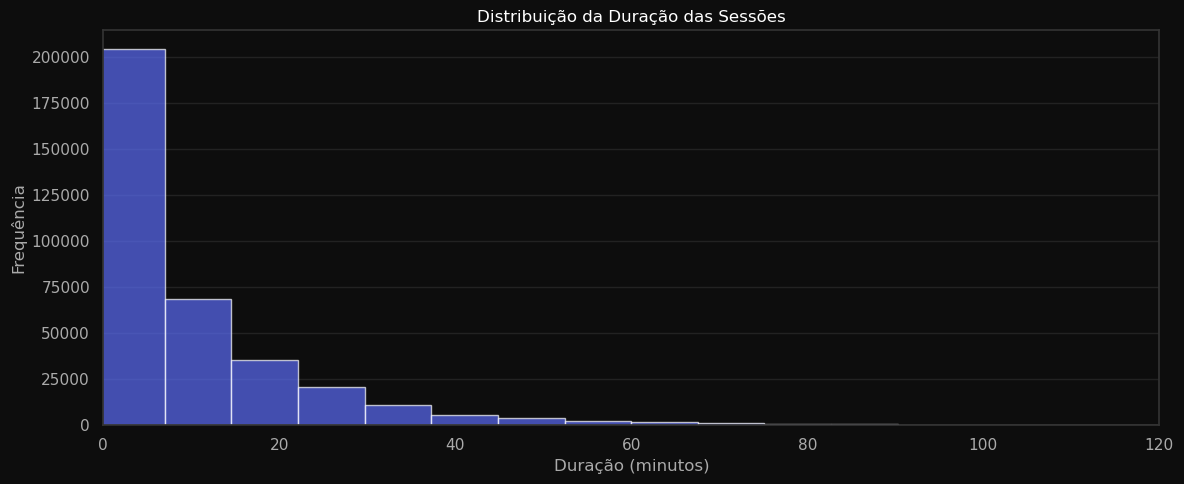

ASL (segundos): 60.00
ASL (minutos):  1.00

0   2017-12-20 17:20:00
1   2018-02-19 16:53:00
2   2017-07-01 01:54:00
3   2018-05-20 10:59:00
4   2017-12-27 14:06:00
5   2017-09-03 21:35:00
6   2018-01-30 11:13:00
7   2017-11-05 15:14:00
8   2017-07-19 10:41:00
9   2017-11-08 13:42:00
Name: start_ts, dtype: datetime64[ns]


In [178]:
# Calculo a duração de cada sessão em segundos
visits['session_duration'] = (visits['end_ts'] - visits['start_ts']).dt.total_seconds()

# Ploto histograma da distribuição de duração (em minutos)
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor('#0d0d0d')
ax.set_facecolor('#0d0d0d')

ax.hist(visits['session_duration'] / 60, bins=100, color='#5B6BF5', alpha=0.7)

ax.set_title('Distribuição da Duração das Sessões', color='white')
ax.set_xlabel('Duração (minutos)', color='#aaaaaa')
ax.set_ylabel('Frequência', color='#aaaaaa')
ax.tick_params(colors='#aaaaaa')
for spine in ax.spines.values():
    spine.set_edgecolor('#333333')
ax.yaxis.grid(True, color='#222222', zorder=0)
ax.set_axisbelow(True)
ax.set_xlim(0, 120)

plt.tight_layout()
plt.show()

# Calculo o ASL — uso moda pois distribuição é assimétrica à direita
asl_sec = visits['session_duration'].mode()[0]
asl_min = asl_sec / 60
print(f'ASL (segundos): {asl_sec:.2f}')
print(f'ASL (minutos):  {asl_min:.2f}')

# Verifico arredondamento dos timestamps
print()
print(visits['start_ts'].head(10))

### Observação — ASL e Qualidade dos Dados

A moda de 60 segundos é um **artefato de coleta**, não comportamento real do usuário. Os timestamps de `start_ts` e `end_ts` estão arredondados para o minuto exato — sessões com duração real entre 1 e 2 minutos ficam registradas como exatamente 60s, inflando artificialmente esse valor na moda.

A ASL de 1 minuto **não deve ser interpretada** como tempo típico de sessão. Para análises que dependam de duração precisa, este arredondamento é uma limitação dos dados que deve ser mencionada na conclusão final.

#### 2.4 Retenção — Sticky Factor e Coortes

**Sticky WAU** = DAU médio ÷ WAU médio × 100  
**Sticky MAU** = DAU médio ÷ MAU médio × 100  

Indica a porcentagem dos usuários da semana/mês que voltam diariamente. Quanto maior, mais engajado é o produto.

**Para o heatmap de retenção por coorte:**
- Agrupo usuários pelo mês da **primeira sessão** (a coorte deles)
- Meço em quais semanas seguintes cada usuário voltou
- Taxa de retenção = usuários ativos na semana T ÷ tamanho da coorte
- Visualizo com `seaborn.heatmap` — linhas = coorte, colunas = age em semanas

**Armadilha que preciso evitar:** não confundo `first_session_date` (para definir a coorte) com `session_date` (para calcular o age).  
O age de cada visita é em relação à **primeira sessão daquele usuário**, não do período inteiro.

**Pergunta:** como vou identificar a primeira sessão de cada usuário para definir a qual coorte ele pertence?

Sticky WAU: 15.88%
Sticky MAU: 3.91%

age                   0         1         2         3         4         5   \
first_session_month                                                          
2017-06              1.0  0.078664  0.053775  0.061392  0.068557  0.071423   
2017-07              1.0  0.056088  0.051294  0.056164  0.058219  0.048174   
2017-08              1.0  0.076908  0.062862  0.062764  0.050093  0.044004   
2017-09              1.0  0.085489  0.069205  0.050706  0.039392  0.037835   
2017-10              1.0  0.078608  0.052239  0.038958  0.034261  0.032221   

age                        6         7         8         9         10  \
first_session_month                                                     
2017-06              0.061015  0.057772  0.052342  0.050833  0.040652   
2017-07              0.045358  0.045738  0.038813  0.028615  0.027473   
2017-08              0.036342  0.039485  0.027895  0.026029       NaN   
2017-09              0.035860  0.024186  0.022809 

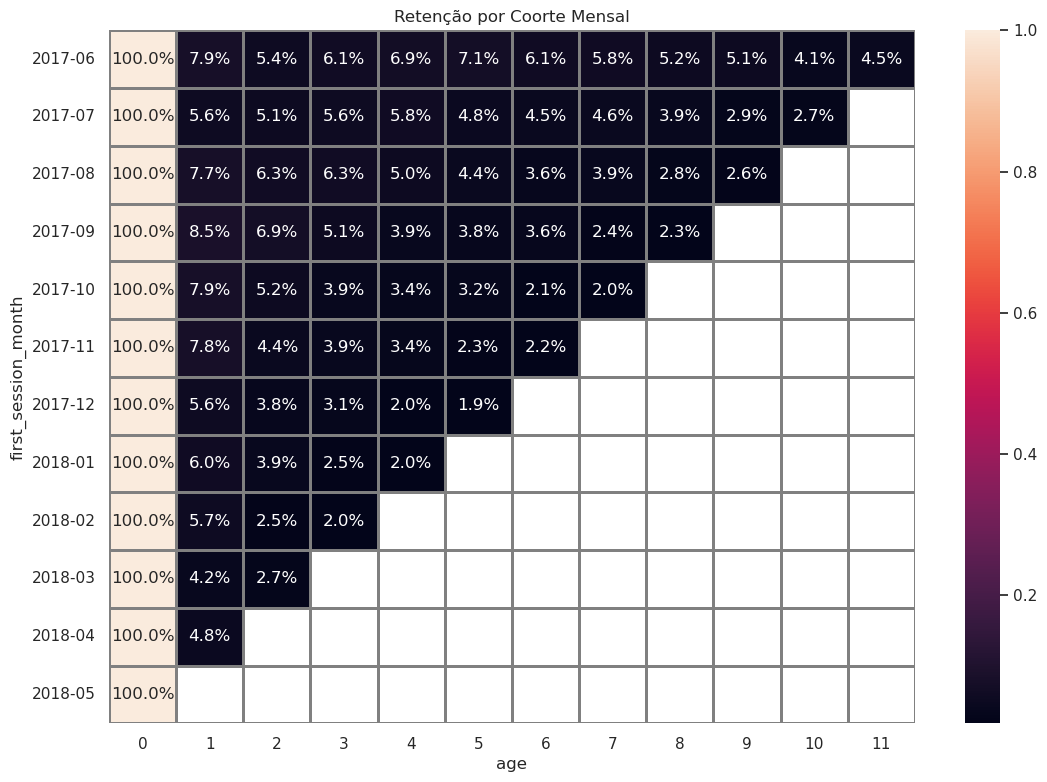

In [179]:
# Calculo Sticky WAU e Sticky MAU
sticky_wau = (dau_total / wau_total) * 100
sticky_mau = (dau_total / mau_total) * 100

print(f'Sticky WAU: {sticky_wau:.2f}%')
print(f'Sticky MAU: {sticky_mau:.2f}%')

# Heatmap de retenção por coorte mensal
# Passo 1: identifico a primeira sessão por uid (padrão join)
first_session_ts = visits.groupby('uid')['start_ts'].min()
first_session_ts.name = 'first_session_ts'
visits = visits.join(first_session_ts, on='uid')
visits['first_session_month'] = visits['first_session_ts'].dt.to_period('M').dt.to_timestamp()

# Passo 2: age em meses inteiros
visits['age'] = ((visits['session_month'] - visits['first_session_month']).dt.days / 30.44).round().astype(int)

# Passo 3: usuários únicos por (coorte, age)
cohort_counts = visits.groupby(['first_session_month', 'age'])['uid'].nunique()

# Passo 4: preparo cohort_df e tamanho das coortes (age == 0)
cohort_df = cohort_counts.reset_index(name='n_users')
cohort_zero = cohort_df[cohort_df['age'] == 0][['first_session_month', 'n_users']].rename(columns={'n_users': 'cohort_size'})

# Passo 5: merge e cálculo da retenção
cohort_df = cohort_df.merge(cohort_zero, on='first_session_month')
cohort_df['retention'] = cohort_df['n_users'] / cohort_df['cohort_size']

# Passo 6: pivot — linhas = coorte, colunas = age, valores = retenção
retention_pivot = cohort_df.pivot_table(
    index='first_session_month',
    columns='age',
    values='retention',
    aggfunc='sum'
)

# Formata o índice para exibir apenas ano-mês no heatmap
retention_pivot.index = retention_pivot.index.strftime('%Y-%m')

print()
print(retention_pivot.head(5))

# Passo 7: heatmap de retenção
sns.set(style='white')
plt.figure(figsize=(13, 9))
sns.heatmap(
    retention_pivot,
    annot=True,
    fmt='.1%',
    linewidths=1,
    linecolor='gray'
)
plt.title('Retenção por Coorte Mensal')
plt.show()

### O que o heatmap confirma:

A retenção cai de forma consistente em todas as coortes — de ~6-8% no mês 1 para menos de 3% no mês 6. Nenhuma coorte apresenta recuperação, o que indica baixo engajamento recorrente estrutural. Isso reforça a necessidade de análise de marketing: é mais eficiente reter usuários existentes do que adquirir novos se o produto não gera recompra;

A coorte de junho/2017 tem a maior retenção de longo prazo (~4.5% no mês 11) — pode ser a base mais fiel ou um efeito de sazonalidade;

Um detalhe importante na análise: a queda grande não é necessariamente problema de produto isolado — pode ser reflexo direto do que já foi visto no DAU/MAU: o usuário típico visita uma vez por mês. O heatmap confirma esse padrão estruturalmente.

### Vendas

#### 2.5 Quando os Usuários Começam a Comprar

Vou medir quanto tempo passa entre a **primeira sessão** do usuário e sua **primeira compra**.

**Classificação em faixas:**
- **0 dias** — comprou no mesmo dia da primeira visita
- **1 dia** — comprou no dia seguinte
- **7 dias** — comprou dentro de uma semana
- **30+ dias** — levou mais de um mês para converter

Para isso, preciso cruzar `visits` (primeira sessão por uid) com `orders` (primeira compra por uid).  
Uso `how='inner'` para manter apenas usuários que fizeram as duas coisas.

**Armadilha:** `buy_ts - first_session_ts` resulta em Timedelta — converto para dias antes de classificar.

**Pergunta:** como vou identificar a primeira compra de cada usuário em `orders`?

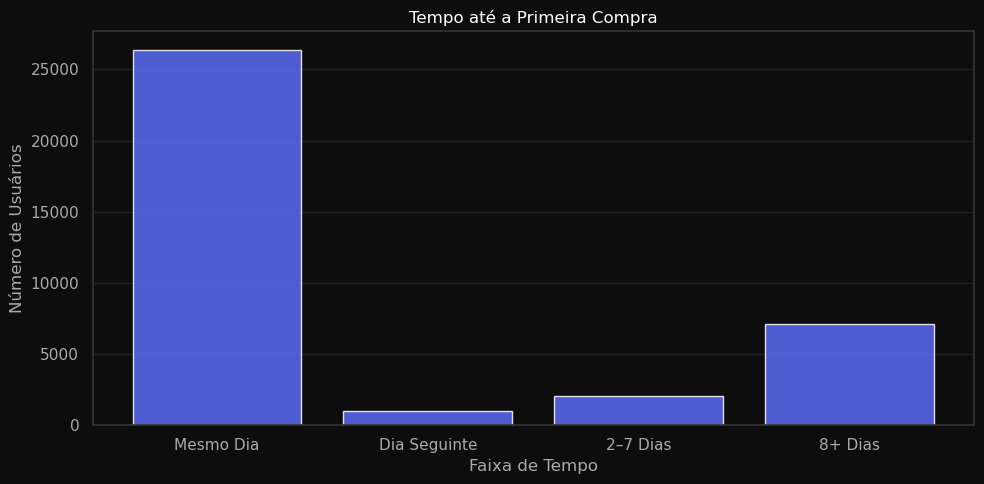

In [180]:
# Identifico a primeira sessão de cada uid em visits
# reaproveito coluna 'first_session_ts' criada no passo anterior

first_session = visits[['uid', 'first_session_ts']].drop_duplicates()

# Identifico a primeira compra de cada uid em orders
# groupby('uid')['buy_ts'].min() -> reset_index() -> renomeio para 'first_buy_ts'

first_buy = orders.groupby('uid')['buy_ts'].min().reset_index().rename(
    columns={'buy_ts': 'first_buy_ts'})

# Faço merge: first_session + first_buy pelo uid

first_interactions = pd.merge(first_session, first_buy, on='uid')

# Calculo o tempo até a primeira compra: first_buy_ts - first_session_ts

first_interactions['days_to_purchase'] = (
    first_interactions['first_buy_ts'] - first_interactions['first_session_ts']
).dt.days

# Classifico em faixas
# Faixas: 0d, 1d, 7d, 30d+

same_day    = first_interactions[first_interactions['days_to_purchase'] == 0]
next_day    = first_interactions[first_interactions['days_to_purchase'] == 1]
within_week = first_interactions[(first_interactions['days_to_purchase'] >= 2) & 
                                (first_interactions['days_to_purchase'] <= 7)]
thirty_plus = first_interactions[first_interactions['days_to_purchase'] > 7]

# Ploto gráfico de barras com a distribuição das faixas

labels = ['Mesmo Dia', 'Dia Seguinte', '2–7 Dias', '8+ Dias']
counts = [len(same_day), len(next_day), len(within_week), len(thirty_plus)]

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('#0d0d0d')
ax.set_facecolor('#0d0d0d')

ax.bar(labels, counts, color='#5B6BF5', alpha=0.85)

ax.set_title('Tempo até a Primeira Compra', color='white')
ax.set_xlabel('Faixa de Tempo', color='#aaaaaa')
ax.set_ylabel('Número de Usuários', color='#aaaaaa')
ax.tick_params(colors='#aaaaaa')
for spine in ax.spines.values():
    spine.set_edgecolor('#333333')
ax.yaxis.grid(True, color='#222222', zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

+ Observando o gráfico, identifico uma concentração expressiva de conversões no mesmo dia (~26.000 usuários) — o que indica um perfil de usuário com intenção clara de compra: chega à plataforma já sabendo o que quer.

+ A queda abrupta no dia seguinte e na faixa 2-7 dias (~900 e ~1.700) sugere que quem não converte no mesmo dia tende a abandonar. Identifico aqui uma oportunidade de remarketing nessa janela.

+ A faixa 8+ dias (~7.000 usuários) é relevante — indica uma parcela que voltou após um tempo, possivelmente após comparar preços ou ser impactado por alguma campanha.

+ Como implicação para o marketing: o maior retorno de campanha deve estar no mesmo dia (urgência, chamadas diretas). A faixa 8+ reforça que campanhas de médio prazo também têm efeito mensurável.

#### 2.6 Pedidos por Cliente e Ticket Médio

**Pedidos por cliente:** vou contar quantas compras cada `uid` fez no período.  
**Ticket médio:** vou calcular o valor médio de `revenue` por pedido individual.

**Atenção:** ticket médio é a média do valor de cada transação.  
Não divido a receita total pelo número de clientes — divido pelo número de **pedidos**.

**Pergunta:** A média representa bem o comportamento típico? O que faço para deixar isso claro na análise?

In [181]:
# Calculo pedidos por cliente:

orders_per_customer = orders.groupby('uid')['buy_ts'].count().mean()

# Calculo o ticket médio:
# orders['revenue'].mean()
# calculo também a mediana para comparar — orders['revenue'].median()
mean_revenue = orders['revenue'].mean()
median_revenue = orders['revenue'].median()

print(f"Média de pedidos por cliente: {orders_per_customer}\n")
print(f"Ticket médio: {mean_revenue}\n")
print(f"Ticket mediano: {median_revenue}\n")
# extra

print(f"Ticket modal: {orders['revenue'].mode().iloc[0]}\n")

Média de pedidos por cliente: 1.3803630588943954

Ticket médio: 4.99964714050293

Ticket mediano: 2.5

Ticket modal: 1.8300000429153442



### Observação:

Com moda US 1.83, mediana US 2.50 e média US 5.00 existem três métricas apontando na mesma direção:

+ A moda (valor mais frequente) é US 1.83 — o ticket mais comum é muito baixo
+ A mediana US 2.50 confirma que metade dos pedidos está abaixo desse valor
+ A média US 5.00 está inflada por poucos pedidos de alto valor

Isso prova que a base de receita da Y.Afisha é concentrada em transações de baixo valor, com uma cauda de clientes que gastam um pouco mais e que distorce a média. Para o marketing, isso é relevante: origens com CAC elevado podem não se pagar se o ticket típico do cliente adquirido for próximo de US 1.83 — o ROMI dessas origens tende a ser negativo. (Farei uma análise a seguir)

#### 2.7 LTV por Coorte

**LTV (Lifetime Value):** lucro bruto acumulado por cliente médio ao longo do tempo.

**Pipeline que vou seguir — nesta ordem:**

1. **`first_orders`** — identifico a primeira compra de cada `uid`
2. **`cohort_sizes`** — conto quantos `uid` únicos compraram pela primeira vez em cada mês
3. Calculo `order_month` para cada pedido em `orders`
4. Calculo `age` = meses entre `order_month` e `first_order_month` do uid
5. Calculo `gp` = receita total agrupada por (coorte, age)
6. `ltv = gp ÷ n_buyers` da coorte
7. Pivot: linhas = coortes, colunas = age → `cumsum(axis=1)` para LTV acumulado
8. Coorte média = `.mean(axis=0)` no pivot

**Armadilhas que preciso evitar:**
- **Nunca** calculo LTV como média de médias — sempre `gp ÷ n_buyers`
- **Timedelta em meses:** `(order_month - first_order_month).dt.days / 30.44` → `.round().astype('int')`
- **Extração de mês:** `pd.to_datetime(col).dt.to_period('M').dt.to_timestamp()` — padrão sem warnings

**Pergunta:** por que divido o lucro pelo `n_buyers` da coorte e não pelo número de pedidos naquele mês?

age
0      4.801682
1      5.395666
2      5.821811
3      6.689763
4      7.298634
5      7.969053
6      8.387686
7      9.083583
8     10.062084
9      9.251340
10    10.004616
11    11.879234
dtype: float64


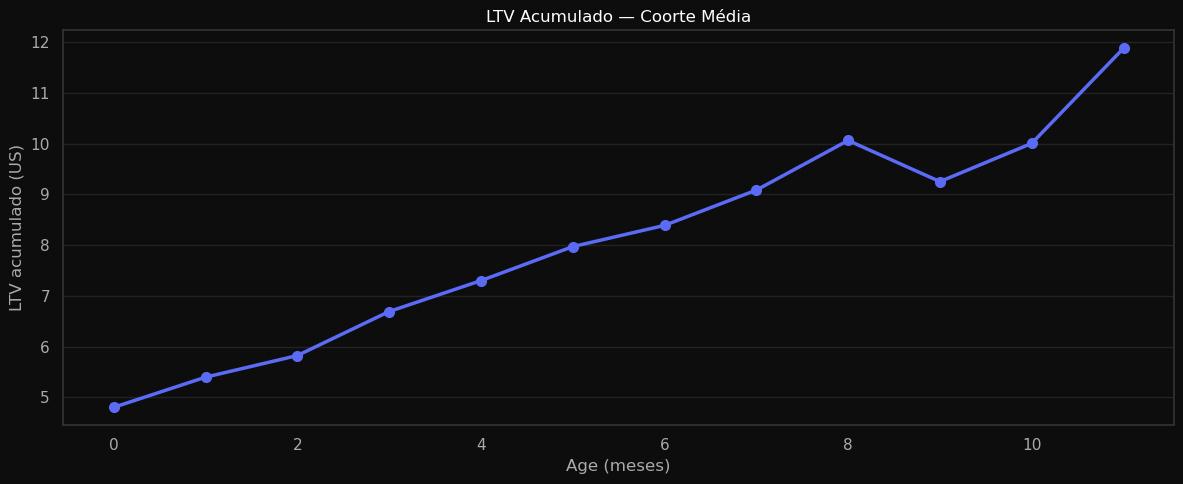

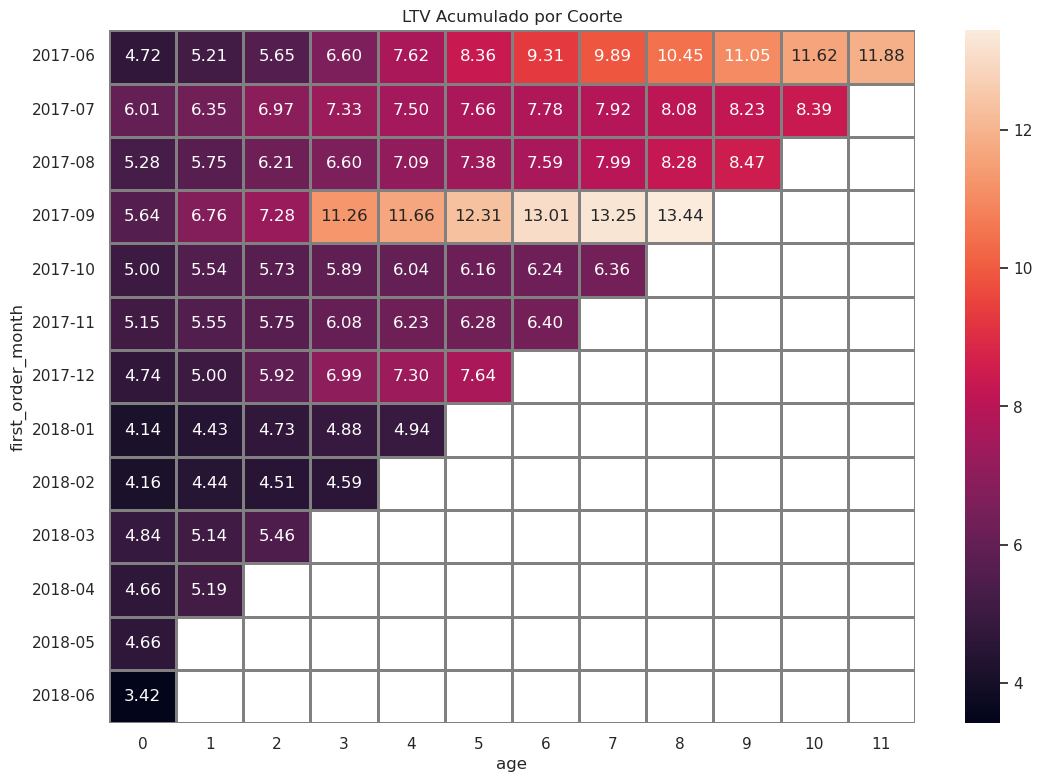

In [182]:
# Passo 1: first_orders — identifico a primeira compra por uid

first_orders = orders.groupby('uid')['buy_ts'].min().reset_index()
first_orders = first_orders.rename(columns={'buy_ts': 'first_buy_ts'})
first_orders['first_order_month'] = first_orders['first_buy_ts'].dt.to_period('M').dt.to_timestamp()

# Passo 2: cohort_sizes — conto n_buyers por mês de primeira compra
# Renomeio para 'n_buyers'

cohort_sizes = first_orders.groupby('first_order_month')['uid'].nunique().reset_index(name='n_buyers')

# Passo 3: calculo order_month para cada pedido em orders
# Já temos a coluna 'buy_ts' convertida para datetime desde a otimização inicial

orders['order_month'] = orders['buy_ts'].dt.to_period('M').dt.to_timestamp()

# Passo 4: faço merge de orders com first_orders pelo uid

orders = orders.merge(first_orders[['uid', 'first_order_month']], on='uid')

# Passo 5: calculo o age em meses inteiros

orders['age'] = ((orders['order_month'] - orders['first_order_month'])
                .dt.days / 30.44).round().astype(int)

# Passo 6: calculo gp — receita total por (first_order_month, age)

gp = orders.groupby(['first_order_month', 'age'])['revenue'].sum().reset_index(name='revenue')

# Passo 7: faço merge com cohort_sizes para trazer n_buyers
# Calculo ltv = revenue / n_buyers

gp = gp.merge(cohort_sizes, on='first_order_month')
gp['ltv'] = gp['revenue'] / gp['n_buyers']

# Passo 8: crio pivot — linhas = first_order_month, colunas = age, valores = ltv
# Aplico .cumsum(axis=1) para LTV acumulado e depois .mean(axis=0)

pivot_ltv = gp.pivot_table(
    index='first_order_month',
    columns='age',
    values='ltv',
    aggfunc='sum'
).cumsum(axis=1)

cohort_ltv_mean = pivot_ltv.mean(axis=0)
print(cohort_ltv_mean)

# Gráfico 1: linha do LTV acumulado da coorte média ao longo dos meses

fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor('#0d0d0d')
ax.set_facecolor('#0d0d0d')

ax.plot(cohort_ltv_mean.index, cohort_ltv_mean.values,
        color='#5B6BF5', linewidth=2.5, marker='o', markersize=7)

ax.set_title('LTV Acumulado — Coorte Média', color='white')
ax.set_xlabel('Age (meses)', color='#aaaaaa')
ax.set_ylabel('LTV acumulado (US)', color='#aaaaaa')
ax.tick_params(colors='#aaaaaa')
for spine in ax.spines.values():
    spine.set_edgecolor('#333333')
ax.yaxis.grid(True, color='#222222', zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Gráfico 2: heatmap do LTV acumulado por coorte e age

pivot_ltv.index = pivot_ltv.index.strftime('%Y-%m')
sns.set(style='white')
plt.figure(figsize=(13, 9))
plt.title('LTV Acumulado por Coorte')
sns.heatmap(
    pivot_ltv.round(2),
    annot=True,
    fmt='.2f',
    linewidths=1,
    linecolor='gray'
)
plt.show()

### Observação — LTV Acumulado por Coorte

Analisando o heatmap, identifico que a coorte de setembro/2017 apresenta um crescimento significativamente diferente das demais — salta de US 5.64 no age=0 para US 13.44 no age=8, enquanto a maioria das coortes segue um fluxo mais gradual e constante. Isso pode indicar uma campanha ou evento pontual que trouxe um perfil de cliente mais valioso naquele mês.

As coortes de 2018 entram com LTV inicial baixo (entre US 3 e US 4) e têm menos tempo para acumular — o que naturalmente limita sua contribuição ao LTV total do período.

Na coorte média (gráfico de linha), identifico uma queda em age=9 (US 9.25 vs US 10.06 em age=8). Isso não é um erro de cálculo: no age=9, menos coortes têm dados disponíveis, ocorre porque a coorte de setembro/2017 não possui registros para esse período — o dataset termina antes que esse age seja atingido. Não se trata de dado ausente no sentido de NaN, mas de período inexistente no dataset.


### Marketing

#### 2.8 Gastos Totais por Origem e ao Longo do Tempo

Vou analisar quanto foi investido em cada `source_id` e como esses gastos evoluíram mês a mês.

**Observação importante:**  
Sources 6 e 7 aparecem em `visits` mas **não estão em `costs`** — são origens sem custo registrado (tráfego orgânico ou direto).  
Isso vai impactar o CAC e o ROMI dessas origens nos passos seguintes. Documento isso.

**Pergunta:** olhando os gastos totais por origem, alguma concentra a maior parte do investimento? Isso é um sinal de risco ou de estratégia deliberada?

   source_id          costs
0          1   20833.269531
1          2   42806.039062
2          3  141321.625000
3          4   61073.601562
4          5   51757.101562
5          9    5517.490234
6         10    5822.490234


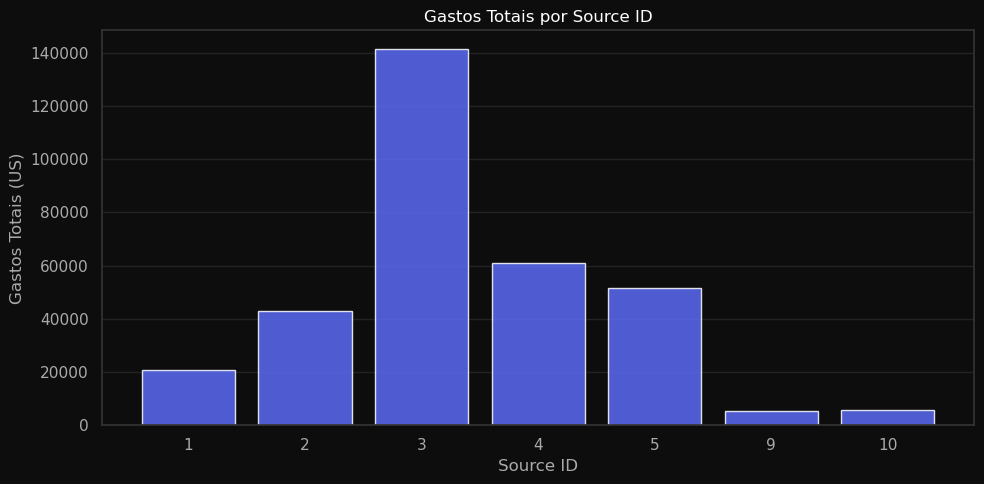

   cost_month  source_id        costs
57 2018-02-01          2  4474.339844
68 2018-03-01          9   480.290009
48 2017-12-01         10   645.859985
4  2017-06-01          5  2616.120117
23 2017-09-01          3  9963.549805
source_id
9       459.790863
10      485.207489
1      1736.105835
2      3567.169922
5      4313.091797
4      5089.466797
3     11776.801758
Name: costs, dtype: float32


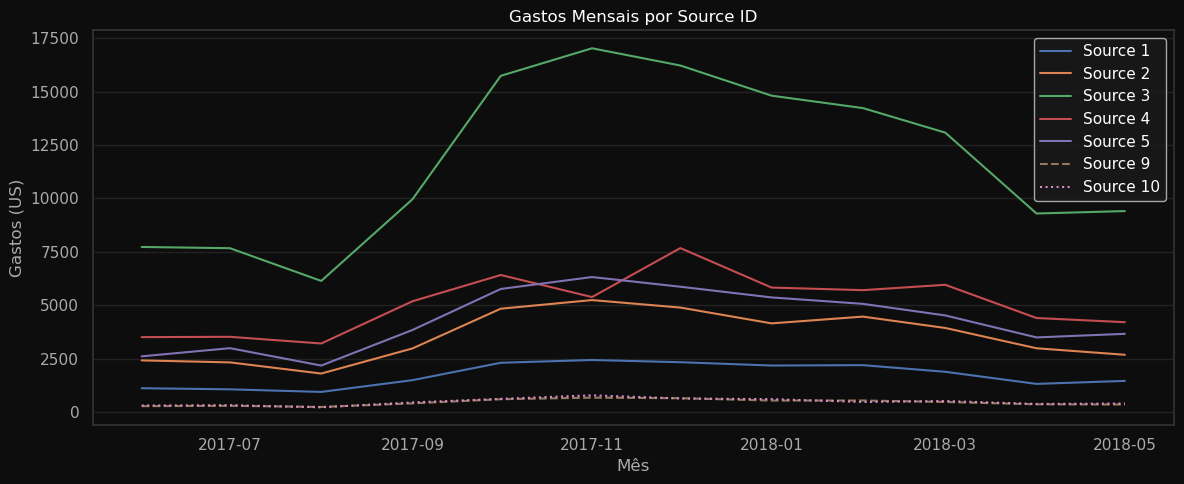

In [183]:
# Calculo o total gasto por source_id:

total_costs = costs.groupby('source_id')['costs'].sum().reset_index()
print(total_costs)

# Ploto gráfico 1: barras com gastos totais por source_id

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('#0d0d0d')
ax.set_facecolor('#0d0d0d')

ax.bar(total_costs['source_id'].astype(str), total_costs['costs'], color='#5B6BF5', alpha=0.85)

ax.set_title('Gastos Totais por Source ID', color='white')
ax.set_xlabel('Source ID', color='#aaaaaa')
ax.set_ylabel('Gastos Totais (US)', color='#aaaaaa')
ax.tick_params(colors='#aaaaaa')
for spine in ax.spines.values():
    spine.set_edgecolor('#333333')
ax.yaxis.grid(True, color='#222222', zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# Calculo os gastos mensais por source_id:

costs['cost_month'] = costs['dt'].dt.to_period('M').dt.to_timestamp()
monthly_costs = costs.groupby(['cost_month', 'source_id'])['costs'].sum().reset_index()
print(monthly_costs.sample(5))
print(monthly_costs.groupby('source_id')['costs'].mean().sort_values())

# Ploto gráfico 2: linhas do gasto por source_id ao longo do tempo
# Uma linha por source_id, legenda clara

fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor('#0d0d0d')
ax.set_facecolor('#0d0d0d')

styles = {1: '-', 2: '-', 3: '-', 4: '-', 5: '-', 9: '--', 10: ':'}

for source in sorted(monthly_costs['source_id'].unique()):
    data = monthly_costs[monthly_costs['source_id'] == source]
    ax.plot(data['cost_month'], data['costs'], 
            linewidth=1.5, linestyle=styles[source], label=f'Source {source}')
ax.set_title('Gastos Mensais por Source ID', color='white')
ax.set_xlabel('Mês', color='#aaaaaa')
ax.set_ylabel('Gastos (US)', color='#aaaaaa')
ax.tick_params(colors='#aaaaaa')
for spine in ax.spines.values():
    spine.set_edgecolor('#333333')
ax.yaxis.grid(True, color='#222222', zorder=0)
ax.set_axisbelow(True)
ax.legend(facecolor='#1a1a1a', labelcolor='white')
plt.tight_layout()
plt.show() 

### Observação — Gastos Totais por Origem

Identifico 7 origens com custo registrado (sources 1, 2, 3, 4, 5, 9 e 10). A numeração não é sequencial — sources 6 e 7 aparecem em visits mas não em costs, indicando tráfego sem custo registrado ou sequencia de classificação de source_id sem padrão de sequência numérica.

O investimento está fortemente concentrado na source 3, que sozinha representa mais de 40% do orçamento total (~US 141.000). As sources 4 e 5 formam o segundo grupo (~US 62.000 e ~US 52.000), seguidas por 2 (~US 43.000) e 1 (~US 21.000). As sources 9 e 10 recebem investimento mínimo (~US 6.000 cada).

Essa concentração em uma única origem é um sinal de risco: se a source 3 não apresentar ROMI positivo, uma parcela significativa do orçamento estará sendo desperdiçada — o que analisarei nos passos seguintes.

+ Após analisar os gastos mensais:

 identifico que a Source 3 apresenta o maior investimento do período, com pico em nov/2017, seguido de queda progressiva — indicando um possível corte de orçamento ou mudança na estratégia de investimentos. Há uma leve recuperação apenas após abril/2018.

As Sources 4 e 5 seguem padrão mais estável ao longo do período, sem grandes variações. As Sources 9 e 10 têm investimento mínimo constante (média de ~US 460–485/mês), praticamente invisíveis no gráfico em comparação com as demais origens e também fazendo com que suas linhas se sobreponham no gráfico mesmo com estilos distintos. Isso reflete os dados reais — reforçando que ambas recebem investimento mínimo e constante ao longo de todo o período.

#### 2.9 CAC por Origem

**CAC (Customer Acquisition Cost):**  
Custo total de marketing de uma origem ÷ novos clientes adquiridos por essa origem.

**Como identifico a origem de cada cliente?**  
A origem está em `visits` no campo `source_id`. Para cada `uid`, uso a origem da **primeira sessão** — atribuição por primeiro contato.

**Armadilha — inner join silencioso:**  
Ao fazer merge de coortes com `costs` por data, se uma coorte não tiver custo registrado naquele mês, o merge `inner` vai **perder silenciosamente** essas coortes.  
Uso `how='left'` e trato os NaN resultantes explicitamente.

**Atenção extra:** sources 6 e 7 não têm custos — o CAC delas é indefinido. Documento esse ponto.

   source_id        cac
0          1   7.212107
1          2  12.504068
2          3  13.802743
3          4   6.439374
4          5   7.451938
5          7        NaN
6          9   5.413892
7         10   4.867125


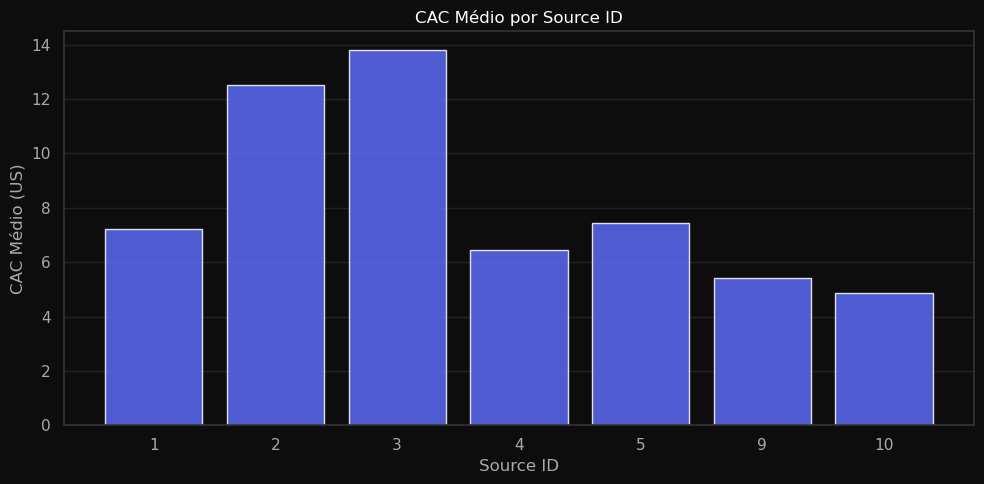

In [184]:
# Identifico a origem da primeira sessão de cada uid:

first_touch = visits.sort_values('start_ts').drop_duplicates(subset='uid', keep='first')[['uid', 'source_id']]

# Faço merge de first_orders com a origem do primeiro contato pelo uid
# Resultado: cada uid com first_order_month e source_id de aquisição

buyers_by_source = first_orders.merge(first_touch, on='uid')

# Calculo novos clientes por (first_order_month, source_id):

new_customers = buyers_by_source.groupby(['first_order_month', 'source_id'])['uid'].nunique().reset_index(name='n_new_customers')

# Calculo custos mensais por source_id: (já tenho costs_monthly da sessão 2.8)

# Faço merge de novos clientes com custos mensais:
# how='left' — não perco coortes sem custo registrado
# Trato NaN nos custos (sources 6 e 7 sem gasto = CAC indefinido)
# Calculo CAC = costs / n_novos_clientes

cac = new_customers.merge(
    monthly_costs,
    left_on=['first_order_month', 'source_id'],
    right_on=['cost_month', 'source_id'],
    how='left'
)

cac['cac'] = cac['costs'] / cac['n_new_customers']
cac_by_source = cac.groupby('source_id')['cac'].mean().reset_index()

print(cac_by_source)

# Ploto gráfico: barras comparando CAC por source_id

cac_plot = cac_by_source.dropna(subset=['cac'])

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('#0d0d0d')
ax.set_facecolor('#0d0d0d')

ax.bar(cac_plot['source_id'].astype(str), cac_plot['cac'], color='#5B6BF5', alpha=0.85)

ax.set_title('CAC Médio por Source ID', color='white')
ax.set_xlabel('Source ID', color='#aaaaaa')
ax.set_ylabel('CAC Médio (US)', color='#aaaaaa')
ax.tick_params(colors='#aaaaaa')
for spine in ax.spines.values():
    spine.set_edgecolor('#333333')
ax.yaxis.grid(True, color='#222222', zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Observação: 

+ Sources 2 e 3 — CAC alto (US 12.50 e US 13.80), concentram a maior parte do investimento e custam mais para adquirir cada cliente
+ Sources 1, 4, 5, 9, 10 — CAC entre US 4.87 e mais que US 7, mais eficientes na aquisição

O ponto crítico: o LTV médio no age=0 é US 4.80. Isso significa que nenhuma source recupera o CAC no primeiro mês — todas dependem de recompra para ser lucrativas. Sources 2 e 3 precisam que o cliente fique mais tempo para compensar o investimento.

Isso é exatamente o que o ROMI vai revelar — em qual mês cada source atinge o payback.

#### 2.10 ROMI por Origem e por Coorte

**ROMI (Return on Marketing Investment):** LTV acumulado ÷ CAC

- **ROMI > 1:** a origem retorna mais do que custa adquirir o cliente
- **ROMI < 1:** a origem está consumindo mais do que retorna
- **ROMI = 1:** ponto de equilíbrio (payback)

**Pipeline que vou seguir:**
1. LTV acumulado por coorte e age — já calculado em 2.7
2. CAC por origem e mês — já calculado em 2.9
3. Combino LTV com CAC pelo par (coorte, source_id)
4. ROMI = LTV acumulado ÷ CAC
5. Pivot + `cumsum(axis=1)` para ver a evolução do ROMI ao longo do tempo

              0     1     2     3     4     5     6     7     8     9    10  \
source_id                                                                     
1          0.87  0.99  1.10  1.20  1.26  1.29  1.33  1.38  1.43  1.45  1.47   
2          0.53  0.64  0.77  0.90  0.96  1.00  1.03  1.04  1.05  1.06  1.07   
3          0.33  0.34  0.36  0.36  0.37  0.37  0.37  0.37  0.38  0.38  0.38   
4          0.71  0.74  0.75  0.77  0.79  0.80  0.83  0.84  0.84  0.85  0.85   
5          0.65  0.68  0.71  0.91  0.94  0.97  0.99  1.00  1.01  1.02  1.02   
7           NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
9          0.72  0.77  0.82  0.86  0.89  0.91  0.93  0.95  0.97  0.98  0.98   
10         0.65  0.66  0.67  0.68  0.68  0.68  0.68  0.69  0.69  0.69   NaN   

             11  
source_id        
1          1.49  
2          1.07  
3          0.38  
4          0.86  
5          1.02  
7           NaN  
9           NaN  
10          NaN  


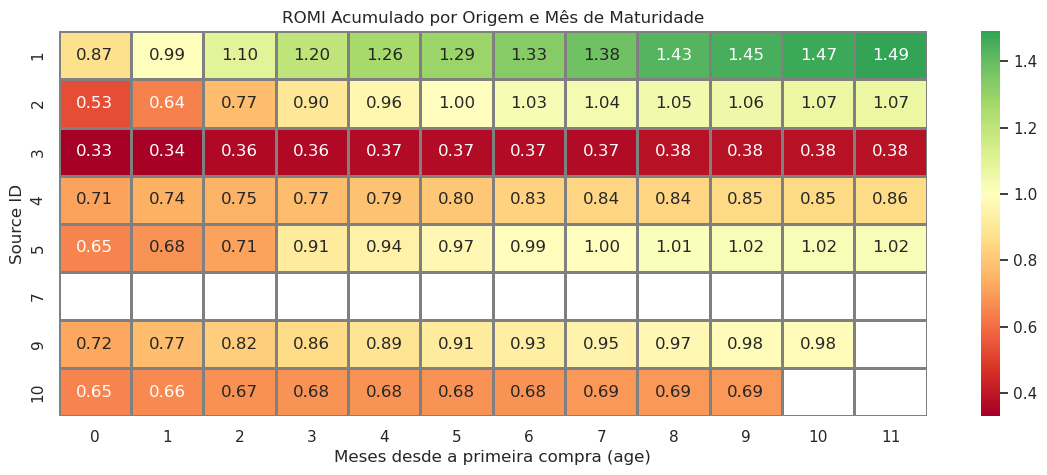

In [185]:
# Calculo ROMI acumulado por origem ao longo do tempo (source_id × age)

orders_attributed = orders.merge(first_touch, on='uid')
revenue_by_source_age = orders_attributed.groupby(['source_id', 'age'])['revenue'].sum().reset_index()
buyers_count = buyers_by_source.groupby('source_id')['uid'].nunique().reset_index(name='n_buyers')

ltv_age = revenue_by_source_age.merge(buyers_count, on='source_id')
ltv_age['ltv'] = ltv_age['revenue'] / ltv_age['n_buyers']

# Pivot: source_id × age, LTV acumulado por coluna
pivot_ltv_src = ltv_age.pivot_table(
    index='source_id',
    columns='age',
    values='ltv',
    aggfunc='sum').cumsum(axis=1)

# Divido cada linha pelo CAC da origem → ROMI acumulado
romi_df = pivot_ltv_src.reset_index().merge(cac_by_source, on='source_id')
for col in pivot_ltv_src.columns:
    romi_df[col] = romi_df[col] / romi_df['cac']
romi = romi_df.drop(columns=['cac']).set_index('source_id')


print(romi.round(2))

sns.set(style='white')
plt.figure(figsize=(14, 5))
plt.title('ROMI Acumulado por Origem e Mês de Maturidade')
sns.heatmap(
    romi.round(2),
    cmap='RdYlGn',
    center=1.0,
    annot=True,
    fmt='.2f',
    linewidths=1,
    linecolor='gray'
)
plt.xlabel('Meses desde a primeira compra (age)')
plt.ylabel('Source ID')
plt.show()

### Observação:
Origens que não se pagam:

+ Source 3 — o maior problema: recebe o maior investimento (~40% do orçamento), mas o ROMI fica estagnado em 0.38 ao longo de todo o período. Nunca se aproxima do breakeven. Cada US 1 investido retorna apenas US 0.38.
+ Source 4 — chega a 0.86 mas não cruza 1.0 no período observado.
+ Source 9 — quase no breakeven (0.98 no age=10), mas não conclui.
+ Source 10 — ROMI praticamente flat desde o início (0.65 → 0.69). Não há crescimento.

Origens lucrativas:

Source 1 — único com ROMI sólido: atinge breakeven no age=2 e cresce até 1.49. É a origem mais eficiente do portfólio.
Source 2 — breakeven no age=5, termina em 1.07. Lucrativo, mas marginal.
Source 5 — breakeven no age=8, termina em 1.02. Quase no limite.


Conclusão central: a maior parte do orçamento está concentrada na pior origem. Source 3 é um desperdício quantificado — e essa é a recomendação principal do passo 3. Opinião sobre seria a seguinte: Source 3 deve ser revisada ou reduzida — redirecionar esse orçamento para Source 1 teria impacto imediato no ROMI geral.

#### 2.11 Comparativo por Dispositivo

Vou comparar o desempenho de **desktop** vs **touch** nas principais métricas:
- Audiência (MAU por device)
- Taxa de conversão (compradores únicos ÷ visitantes únicos por device)
- Ticket médio e LTV
- CAC e ROMI

**Regra que sigo:**  
Para comparar conversão entre dispositivos, somo todos os compradores de cada device, somo todos os visitantes, depois divido.  
Nunca calculo a taxa média individual — isso é média de taxas e é estatisticamente incorreto.

In [186]:
# Calculo visitantes únicos por device:
# extra adicional: uso observed=True para considerar apenas categorias 
# presentes no período

device = visits.groupby('device', observed=True)['uid'].nunique().reset_index(name='unique_visitors')
print(device)

# Calculo compradores por device:
# Faço merge de visits (com device) com orders pelo uid
# groupby('device')['uid'].nunique() -> compradores únicos por device

first_device = visits.sort_values('start_ts').drop_duplicates(subset='uid', keep='first')[['uid', 'device']]
buyers_device = orders[['uid']].drop_duplicates().merge(first_device, on='uid')
buyers_by_device = buyers_device.groupby('device', observed=True)['uid'].nunique().reset_index(name='unique_buyers')
print(f'\nbuyers_by_device:\n{buyers_by_device}')

# Taxa de conversão por device = compradores / visitantes
# Uso totais agregados — não faço média de taxas individuais

conversion = device.merge(buyers_by_device, on='device')
conversion['conversion_rate'] = conversion['unique_buyers'] / conversion['unique_visitors']
print(f'\nconversion:\n{conversion}')

    device  unique_visitors
0  desktop           164523
1    touch            71345

buyers_by_device:
    device  unique_buyers
0  desktop          29211
1    touch           7312

conversion:
    device  unique_visitors  unique_buyers  conversion_rate
0  desktop           164523          29211         0.177550
1    touch            71345           7312         0.102488



ticket_by_device:
    device  avg_revenue
0  desktop     5.163578
1    touch     4.292520

ltv:
    device  total_revenue  unique_buyers       ltv
0  desktop  211329.765625          29211  7.234595
1    touch   40727.429688           7312  5.569944

romi por device:
    device       ltv      romi
0  desktop  7.234595  0.802807
1    touch  5.569944  0.618084


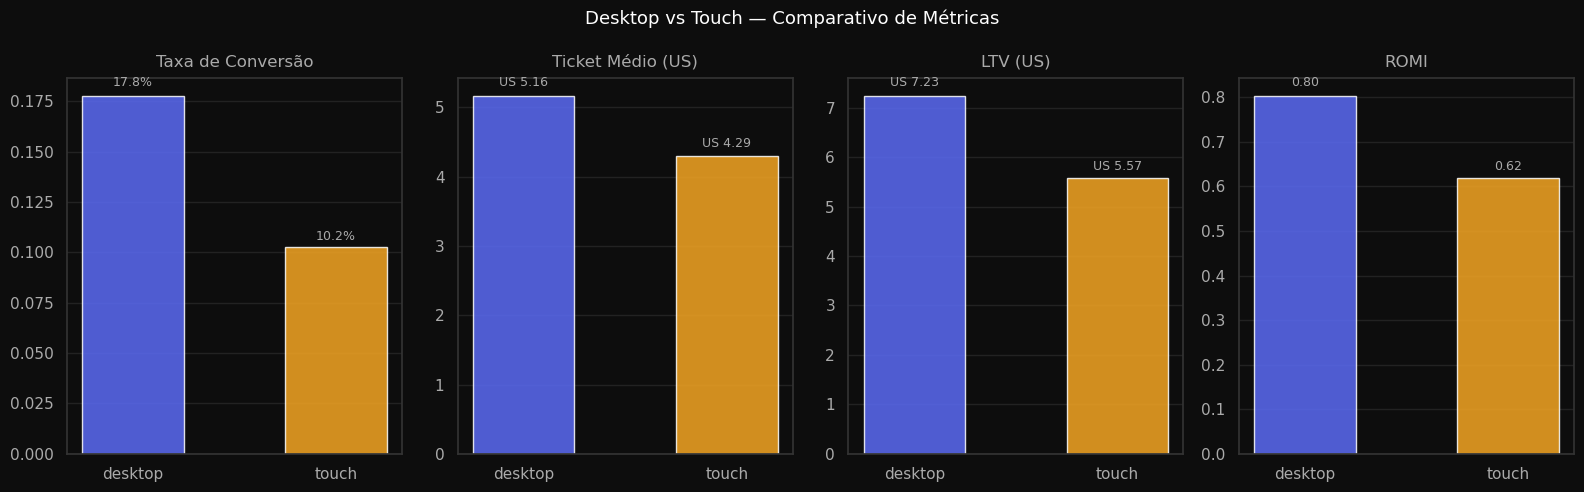

In [187]:
# Calculo ticket médio por device:
# Faço merge de orders com visits (device da primeira sessão) pelo uid
# groupby('device')['revenue'].mean()

orders_device = orders.merge(first_device, on='uid')
ticket_by_device = orders_device.groupby('device', observed=True)['revenue'].mean().reset_index(name='avg_revenue')
print(f'\nticket_by_device:\n{ticket_by_device}')

# Calculo CAC e ROMI por device (reutilizo lógica de 2.9 e 2.10 com device)

ltv_device = orders_device.groupby('device', observed=True)['revenue'].sum().reset_index(name='total_revenue')
ltv_device = ltv_device.merge(buyers_by_device, on='device')
ltv_device['ltv'] = ltv_device['total_revenue'] / ltv_device['unique_buyers']
print(f'\nltv:\n{ltv_device}')

# Não temos cac por device, então calculo o CAC geral para ter uma referência 
# de ROMI

cac_geral = costs['costs'].sum() / first_orders['uid'].nunique()

# uso extra do assign ()

romi_device = ltv_device.assign(
    romi=ltv_device['ltv'] / cac_geral)[['device', 'ltv', 'romi']]
print(f'\nromi por device:\n{romi_device}')

# Ploto gráfico: barras lado a lado comparando desktop vs touch
# Métricas: conversão, ticket médio, CAC, ROMI

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.patch.set_facecolor('#0d0d0d')

metrics = [
    (conversion,     'conversion_rate', 'Taxa de Conversão',  '{:.1%}'),
    (ticket_by_device, 'avg_revenue',   'Ticket Médio (US)',  'US {:.2f}'),
    (ltv_device,     'ltv',             'LTV (US)',           'US {:.2f}'),
    (romi_device,    'romi',            'ROMI',               '{:.2f}'),
]

colors = ['#5B6BF5', '#F5A623']

for ax, (df, col, title, fmt) in zip(axes, metrics):
    ax.set_facecolor('#0d0d0d')
    bars = ax.bar(df['device'], df[col], color=colors, alpha=0.85, width=0.5)
    ax.set_title(title, color='#aaaaaa', pad=8)
    ax.tick_params(colors='#aaaaaa')
    for spine in ax.spines.values():
        spine.set_edgecolor('#333333')
    ax.yaxis.grid(True, color='#222222', zorder=0)
    ax.set_axisbelow(True)
    for bar, val in zip(bars, df[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.02,
                fmt.format(val), ha='center', va='bottom', color='#aaaaaa', fontsize=9)

fig.suptitle('Desktop vs Touch — Comparativo de Métricas', color='white', fontsize=13)
plt.tight_layout()
plt.show()




### Observação:

O desktop supera o touch em todas as métricas analisadas — conversão (17.8% vs 10.2%), ticket médio (US 5.16 vs US 4.29), LTV (US 7.23 vs US 5.57) e ROMI (0.80 vs 0.62). A diferença é expressiva, especialmente na taxa de conversão, onde o desktop converte quase o dobro.

Isso abre duas frentes estratégicas: concentrar ainda mais investimento no desktop, que já demonstra melhor desempenho ou desenvolver políticas específicas para impulsionar o touch — seja com experiência de navegação otimizada, campanhas direcionadas ou ofertas exclusivas para mobile.

Vale notar que o ROMI por device foi calculado com o CAC médio geral, pois a tabela de custos não possui informação de dispositivo. Os valores absolutos não são diretamente comparáveis com o 2.10, mas a diferença relativa entre desktop e touch é válida para orientar decisões futuras e que caminho seguir.

## Passo 3 — Conclusão e Recomendações

**Estrutura que vou seguir — para cada ponto: problema → métrica → valor numérico → recomendação acionável**

---

### 1. Qual origem tem melhor ROMI?

A source 1 é a origem mais eficiente do portfólio: atinge o breakeven já no age=2 e encerra o período com ROMI de 1.49 — ou seja, cada US 1 investido retornou US 1.49. As sources 2 (ROMI 1.07, breakeven no age=5) e 5 (ROMI 1.02, breakeven no age=8) também são lucrativas, mas com margem estreita. São as três únicas origens onde o investimento se paga dentro do período observado.

### 2. Qual dispositivo performa melhor?

O desktop supera o touch em todas as métricas: converte quase o dobro (17.8% vs 10.2%), gera maior ticket médio (US 5.16 vs US 4.29), maior LTV (US 7.23 vs US 5.57) e ROMI mais próximo do breakeven (0.80 vs 0.62). O desktop é claramente o canal mais valioso e merece prioridade nos investimentos.

### 3. Qual coorte tem maior LTV?

A coorte de setembro/2017 se destaca com crescimento expressivo — parte de US 5.64 no age=0 e chega a US 13.44 no age=8, bem acima das demais coortes. As coortes de 2017 em geral apresentam LTV acumulado superior às de 2018, que entraram com valores iniciais menores (entre US 3 e US 4) e tiveram menos tempo para acumular receita no período analisado.

### 4. Onde o marketing está sendo desperdiçado?

A source 3 é o maior problema: concentra ~40% do orçamento total e apresenta ROMI de apenas 0.38 ao longo de todo o período — nunca se aproxima do breakeven. Cada US 1 investido retorna US 0.38. A source 10 também não se paga (ROMI 0.69 estagnado desde o início), e a source 4 chega a 0.86 sem cruzar o breakeven no período observado.

### 5. Recomendação final:

Identifico três ações prioritárias:

Reduzir ou redirecionar a source 3 — maior desperdício do portfólio. Parte desse orçamento redirecionada para a source 1 teria impacto direto no ROMI geral.
Priorizar desktop nas campanhas — melhor conversão, ticket e LTV em todas as métricas. Desenvolver estratégias específicas para melhorar a experiência touch pode ser uma frente paralela de médio prazo.
Trabalhar retenção — a retenção cai para menos de 3% no mês 6 em todas as coortes, e a maioria dos usuários visita a plataforma apenas uma vez por mês. Adquirir novos clientes com CAC alto enquanto a retenção permanece baixa é estruturalmente ineficiente. Investir em retenção reduziria a dependência de aquisição constante e melhoraria o LTV das coortes futuras.